# Exploring the transmission-line fault dataset

This notebook looks at the simulated dataset before any deep learning is done. The goal is to answer three questions: **Is the data clean? Are the classes balanced? What do the signals look like?**

**Data:** one HDF5 file generated by the MATLAB/Simulink model in `simulation/`. It is not stored in this repository (it is large and git-ignored), so create it first and place it at `../data/raw/transmission_fault_dataset.h5`.

**Sections**
1. Load the data and check its shape
2. Data quality: missing values and duplicates
3. Labels: class balance and fault locations
4. Looking at the signals: waveforms, wavelets, spectrum
5. Can the classes be separated? PCA, t-SNE and a quick baseline

## 1. Load the data and check its shape

The file holds three arrays:
- `signals`: the measurements, shape `(samples, time steps, channels)`.
- `fault_class`: the fault type of each sample, an integer from 0 to 10 (0 = no fault; the others are the ten short-circuit types, e.g. AG, BC, ABCG).
- `fault_location`: where on the line the fault happened.

Each sample has **2001 time steps** and **6 channels**: three voltages (Va, Vb, Vc) and three currents (Ia, Ib, Ic). Printing the shapes first is a cheap check that the file loaded as expected.

In [19]:
import h5py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.fft import fft, fftfreq

FILE = "../data/raw/transmission_fault_dataset.h5"

with h5py.File(FILE, "r") as f:
    print("signals:", f["signals"].shape)
    print("fault_class:", f["fault_class"].shape)
    print("fault_location:", f["fault_location"].shape)

signals: (16500, 2001, 6)
fault_class: (16500,)
fault_location: (16500,)


### Load the labels into memory
The labels are small, so we read them fully into NumPy arrays. The signals stay on disk and are read one sample at a time later, because the full array is large.

In [22]:
with h5py.File(FILE, "r") as f:
    y_class = f["fault_class"][:]
    y_loc = f["fault_location"][:]

print(y_class.shape)
print(y_loc.shape)

(16500,)
(16500,)


## 2. Data quality: missing values

Deep-learning models cannot train on `NaN` values, so we scan every sample for them. The scan reads one sample at a time to keep memory use low. The count below shows how many samples are corrupted.

In [10]:
with h5py.File(FILE, "r") as f:
    X = f["signals"]

    nan_samples = []

    for i in range(X.shape[0]):
        if np.isnan(X[i]).any():
            nan_samples.append(i)

print("Corrupted samples:", len(nan_samples))

Corrupted samples: 0


## 3. Labels: class balance

If one class had far more samples than the others, a model could score well by always guessing it. The bar chart shows that **all 11 classes have the same number of samples (1,500 each)**, so accuracy is a fair metric here.

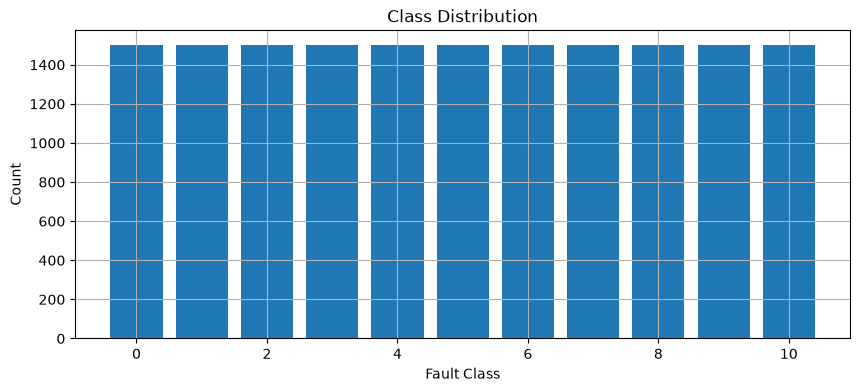

In [11]:
classes, counts = np.unique(y_class, return_counts=True)

plt.figure(figsize=(10,4))
plt.bar(classes, counts)
plt.xlabel("Fault Class")
plt.ylabel("Count")
plt.title("Class Distribution")
plt.grid(True)
plt.show()

### Fault locations
Only faulted samples have a meaningful location, so we keep those with `location >= 0` (the no-fault class is excluded). The histogram shows locations spread roughly evenly along the line, from about 5% to 95% of its length, so no region is over-represented.

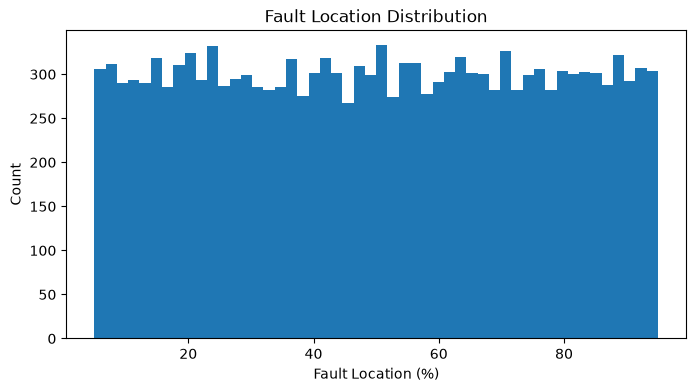

In [5]:
faulted = y_loc[y_loc >= 0]

plt.figure(figsize=(8,4))
plt.hist(faulted, bins=50)
plt.xlabel("Fault Location (%)")
plt.ylabel("Count")
plt.title("Fault Location Distribution")
plt.show()

## 4. Looking at the signals

### One sample, six channels
A single faulted sample (index 510, class 8). The voltages (Va, Vb, Vc) and currents (Ia, Ib, Ic) are drawn on separate axes. In this example the fault begins around time step 1,100 to 1,250: the currents in phases B and C jump to several times their earlier size, while the voltages change much less. Sudden changes like this are what the model learns to detect.

(2001, 6)
8


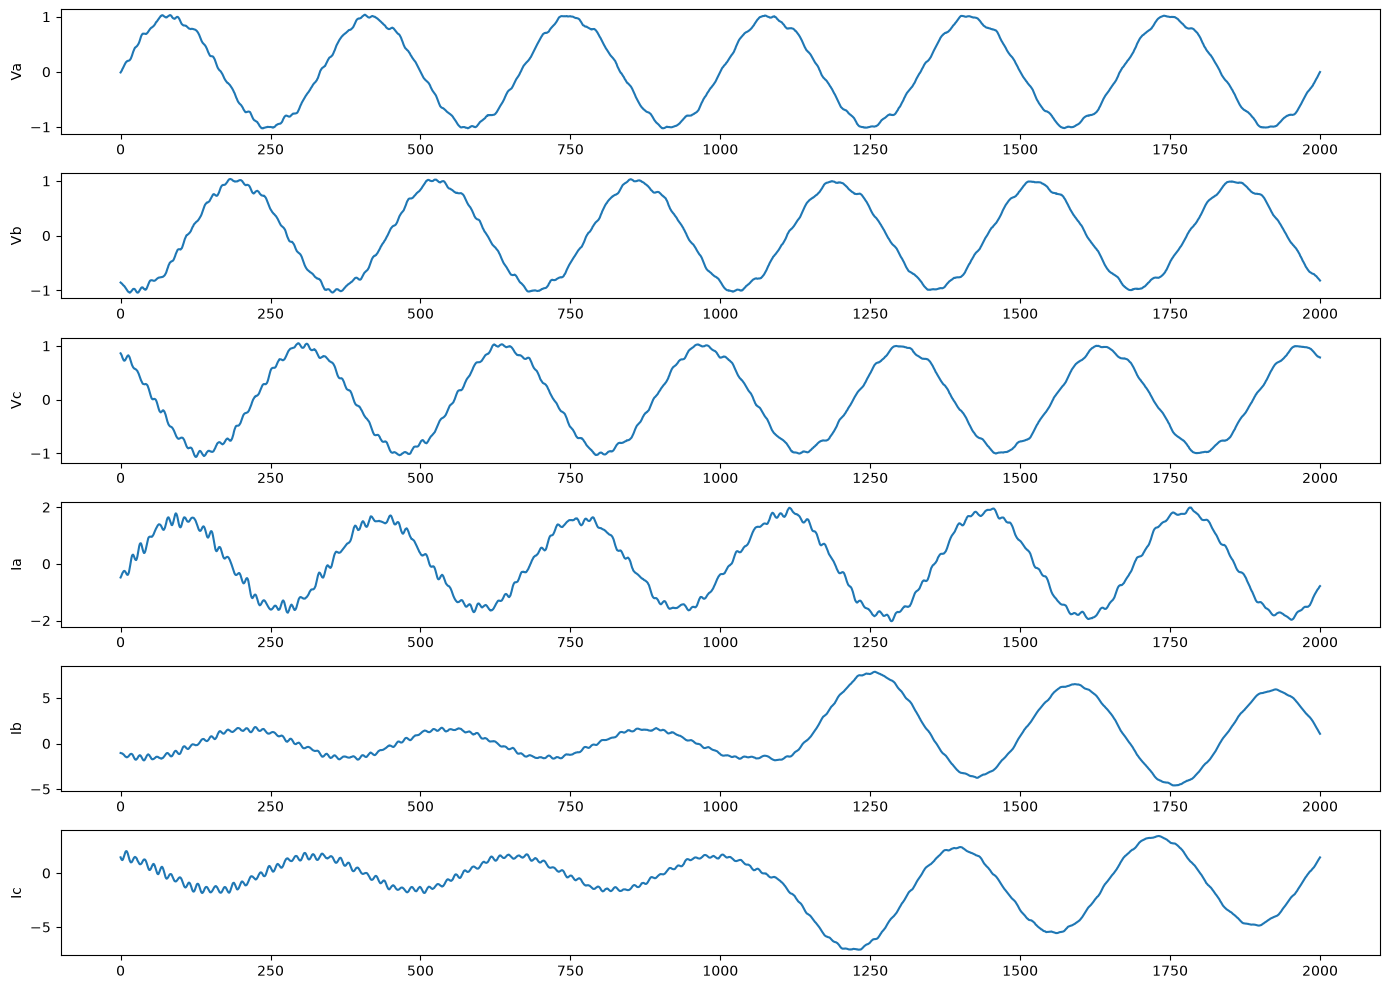

In [24]:
sample_idx = 510

with h5py.File(FILE, "r") as f:
    signal = f["signals"][sample_idx]
    fclass = f["fault_class"][sample_idx]
print(signal.shape)

channel_names = [
    "Va","Vb","Vc",
    "Ia","Ib","Ic"
]

print (fclass)
plt.figure(figsize=(14,10))

for ch in range(6):
    plt.subplot(6,1,ch+1)

    plt.plot(signal[:,ch])

    plt.ylabel(channel_names[ch])

plt.tight_layout()
plt.show()

### Wavelet decomposition
A **discrete wavelet transform** splits a signal into a smooth *approximation* (A4) and several *detail* bands (D4 to D1) that capture fast changes. Fault events show up strongly in the detail bands. This is shown for one channel (Ic) with a 4-level `db4` wavelet, and the printed shapes show how many coefficients each band has.

Approximation: (131,)
Detail L4: (131,)
Detail L3: (256,)
Detail L2: (505,)
Detail L1: (1004,)


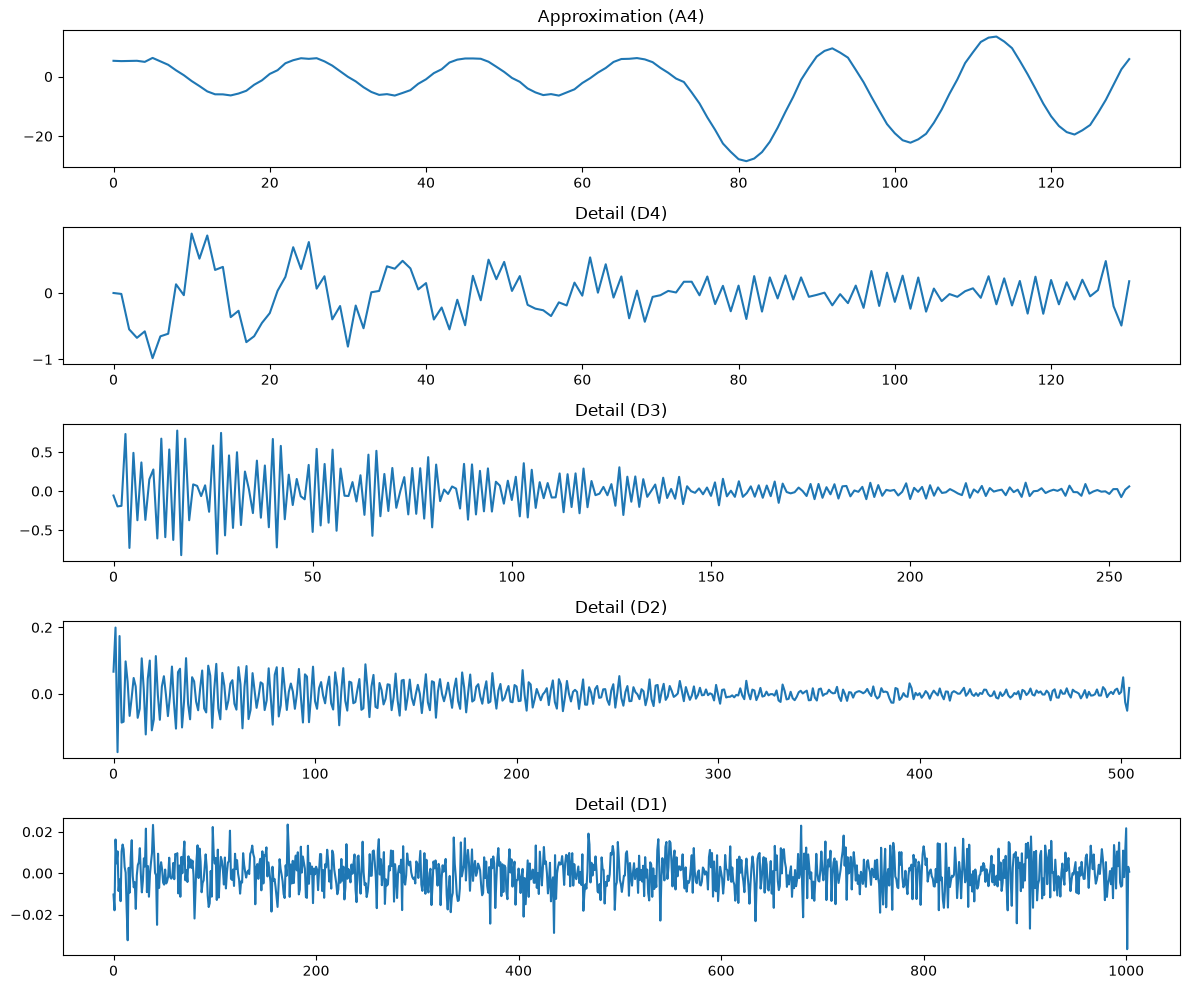

In [30]:
import h5py
import pywt
import matplotlib.pyplot as plt

# Load one sample
with h5py.File(FILE, "r") as f:
    signal = f["signals"][sample_idx]      # (2001, 6)

ic = signal[:, 5]                 # Channel 5 = Ic (phase C current)

# Perform 4-level DWT
coeffs = pywt.wavedec(ic,
                      wavelet='db4',
                      level=4)

# coeffs = [cA4, cD4, cD3, cD2, cD1]
cA4, cD4, cD3, cD2, cD1 = coeffs

print("Approximation:", cA4.shape)
print("Detail L4:", cD4.shape)
print("Detail L3:", cD3.shape)
print("Detail L2:", cD2.shape)
print("Detail L1:", cD1.shape)

fig, ax = plt.subplots(5, 1, figsize=(12, 10))

ax[0].plot(cA4)
ax[0].set_title("Approximation (A4)")

ax[1].plot(cD4)
ax[1].set_title("Detail (D4)")

ax[2].plot(cD3)
ax[2].set_title("Detail (D3)")

ax[3].plot(cD2)
ax[3].set_title("Detail (D2)")

ax[4].plot(cD1)
ax[4].set_title("Detail (D1)")

plt.tight_layout()
plt.show()

### Frequency spectrum (FFT)
The **Fourier transform** shows which frequencies the signal contains. We use the voltage of phase A and plot the 0 to 1000 Hz range. The tall peak is the power-system fundamental frequency, and the small peaks after it are harmonics.

**Check the sampling rate (`Fs`):** the code assumes 2000 Hz, but the waveform above shows only about 6 cycles in 2001 samples while the system runs at 60 Hz (see `configuration/config.yaml`). That suggests the real sampling rate is different. Set `Fs` to the rate used in the Simulink model before reading the frequency axis in Hz.

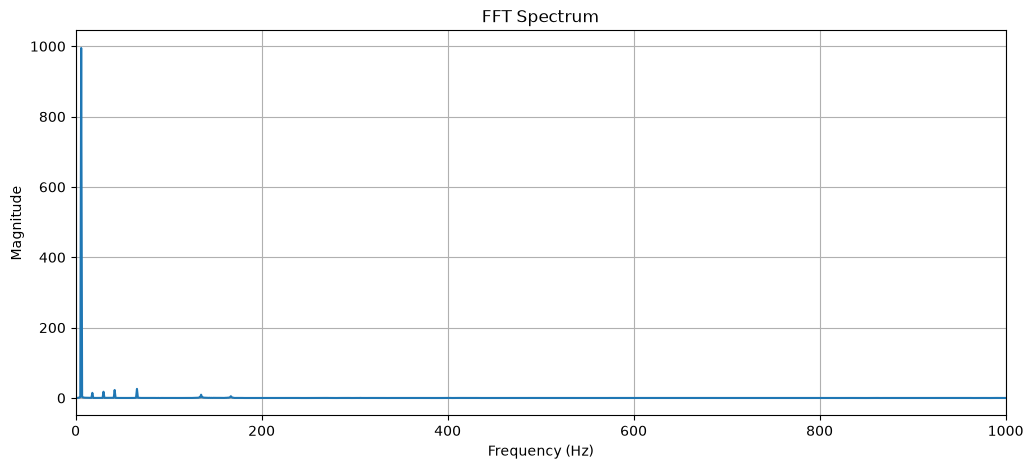

In [25]:
from scipy.fft import fft, fftfreq
import matplotlib.pyplot as plt
import numpy as np

va = signal[:,0]

N = len(va)

Fs = 2000  # Hz

fft_vals = np.abs(fft(va))

freqs = fftfreq(N, d=1/Fs)

mask = freqs >= 0

plt.figure(figsize=(12,5))

plt.plot(
    freqs[mask],
    fft_vals[mask]
)

plt.xlabel("Frequency (Hz)")
plt.ylabel("Magnitude")
plt.title("FFT Spectrum")

plt.xlim(0,1000)

plt.grid(True)

plt.show()

### Voltage A across random samples
Five random samples of Va drawn on one plot. This gives a feel for how much the signals vary from sample to sample (different fault types, inception angles and resistances).

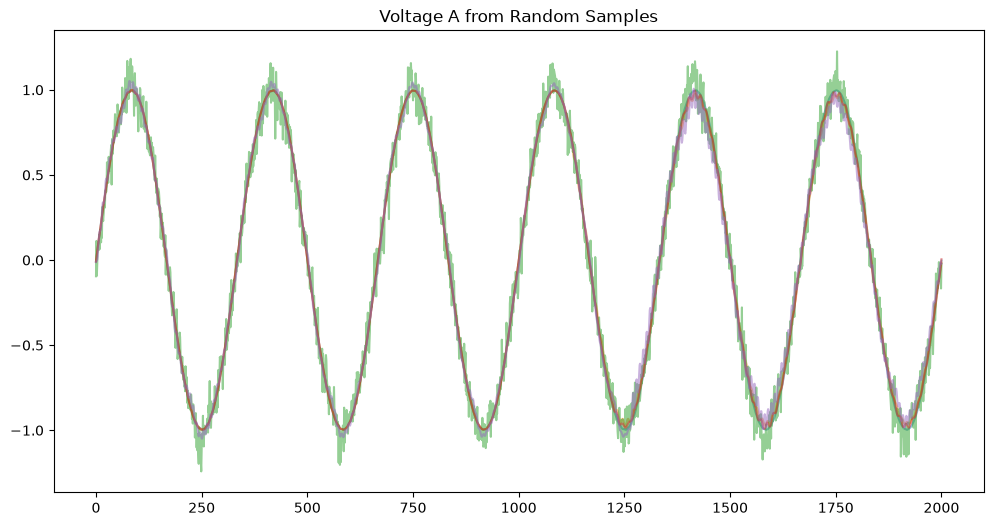

In [8]:
with h5py.File(FILE,"r") as f:

    plt.figure(figsize=(12,6))

    for idx in np.random.choice(16500,5):

        signal = f["signals"][idx]

        plt.plot(signal[:,0], alpha=0.5)

plt.title("Voltage A from Random Samples")
plt.show()

### One example of each fault type
For every class we plot the three phase voltages of the first sample. Compare the classes: for example, in a fault involving phase A the voltage on phase A behaves differently from the healthy phases. These visual differences are what the model has to learn.

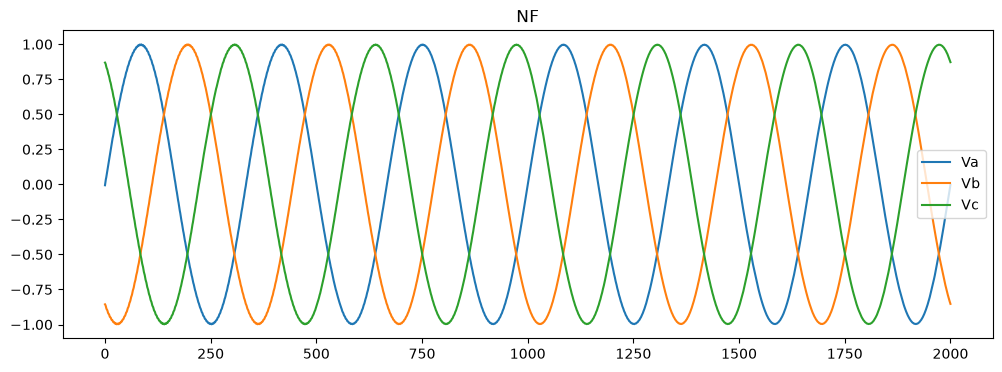

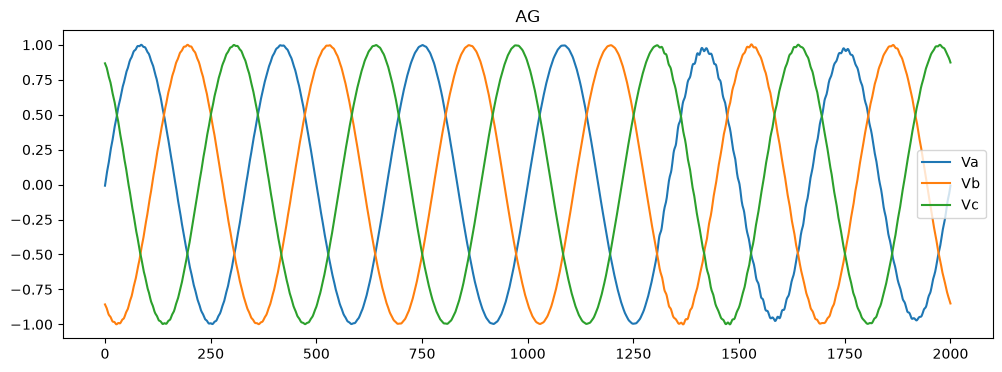

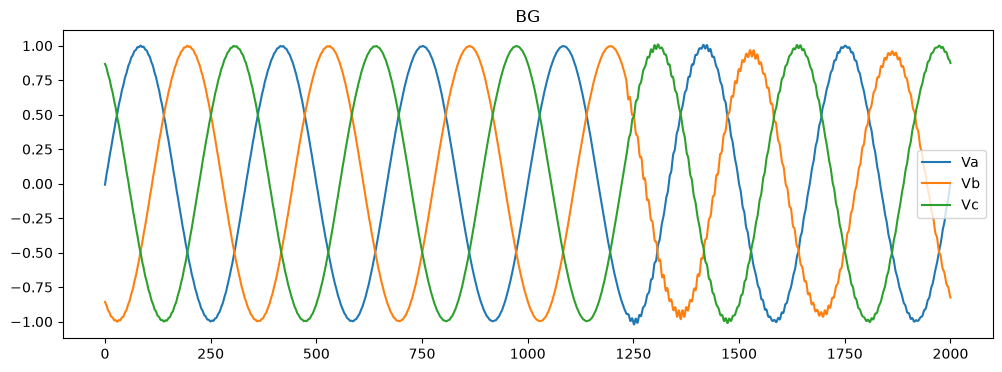

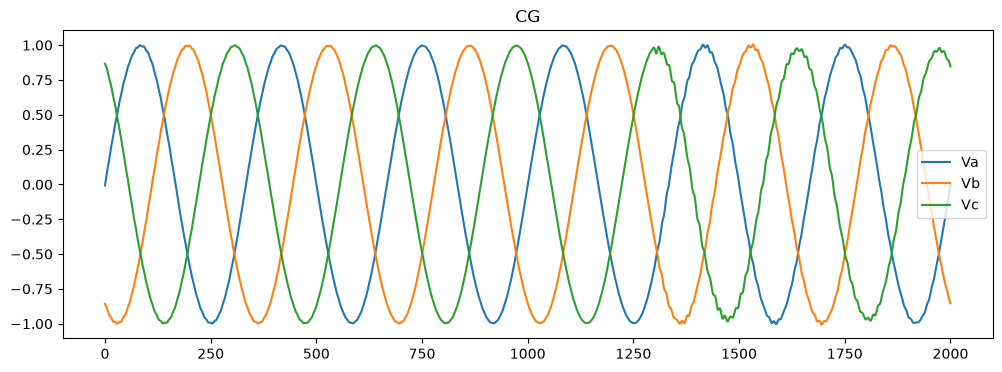

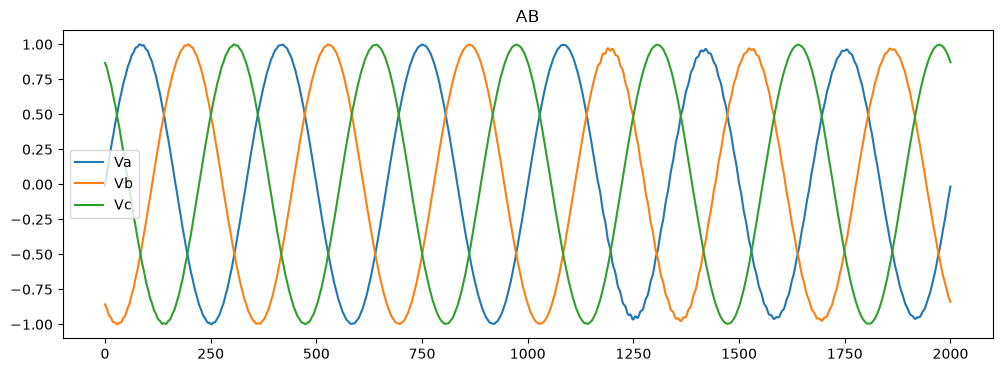

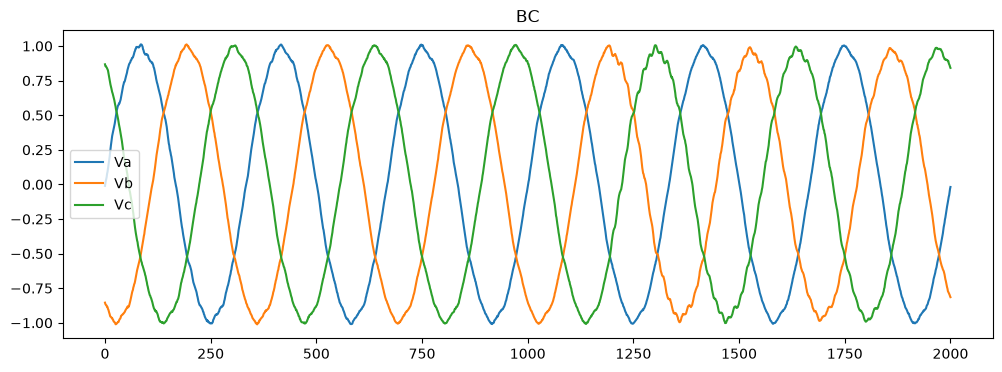

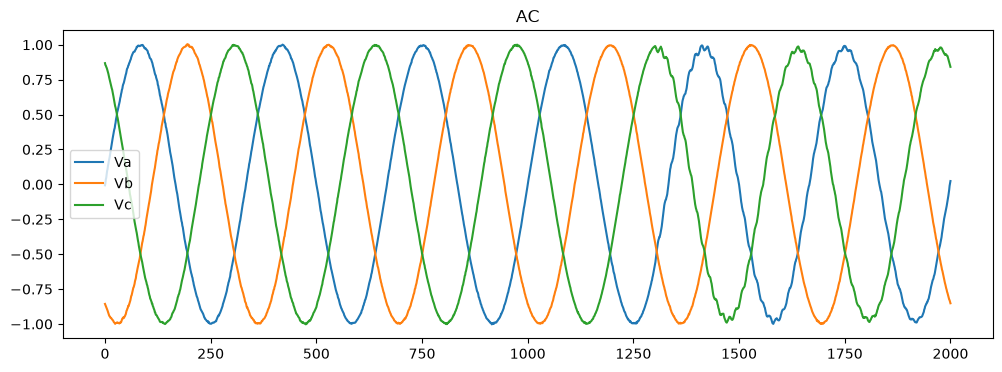

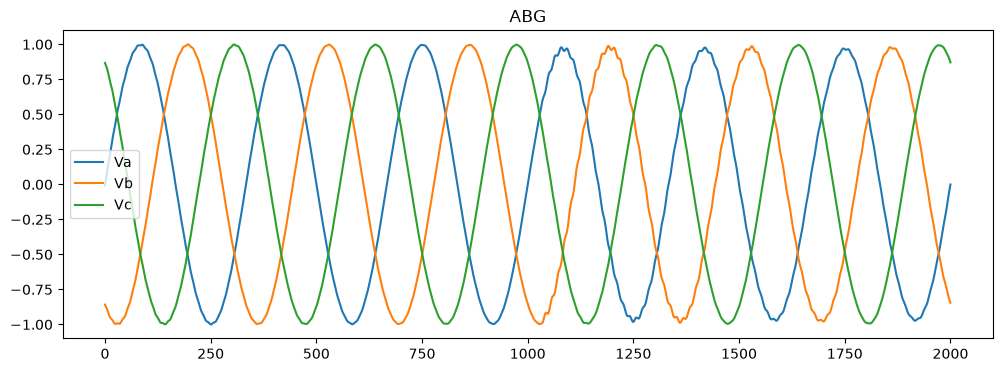

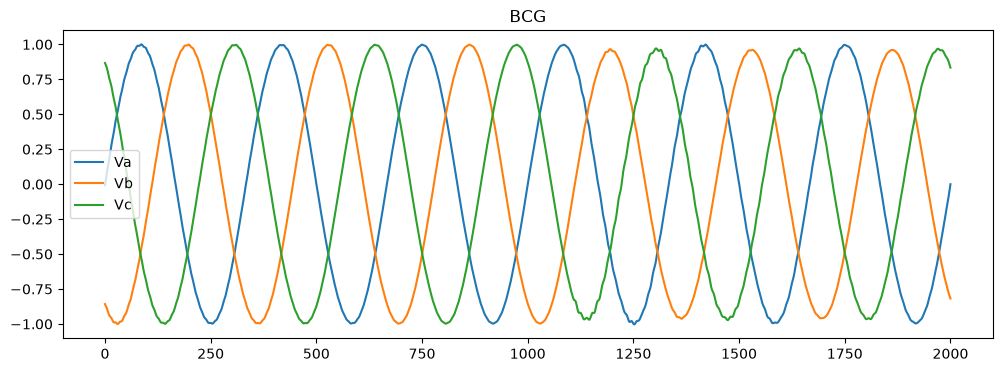

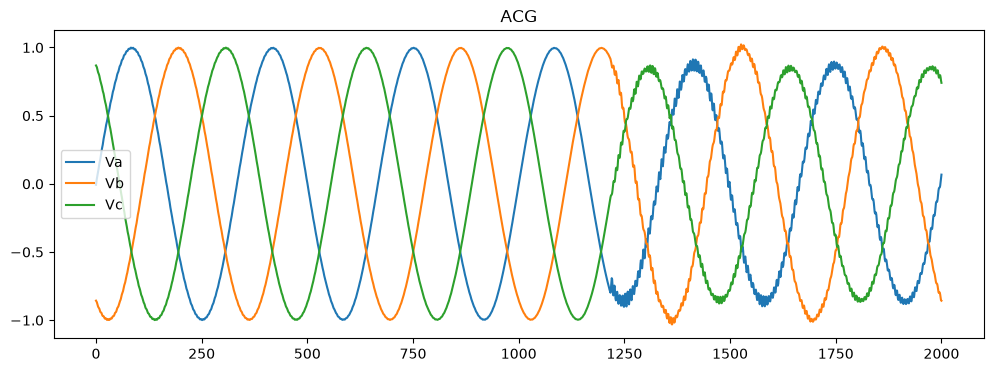

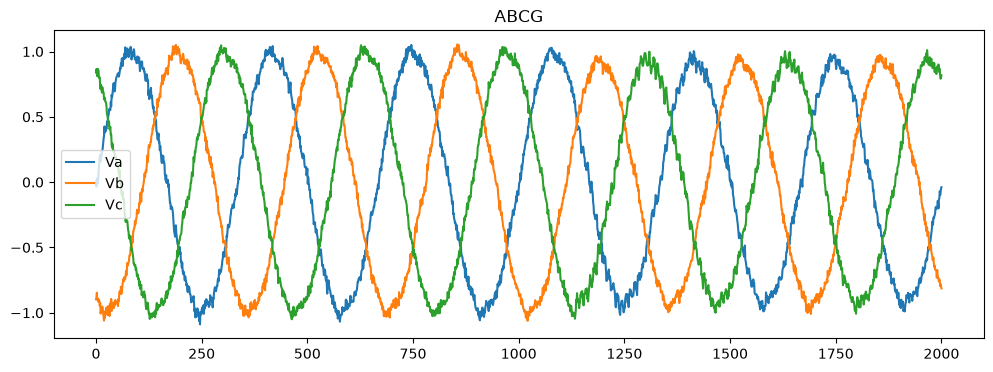

In [9]:
class_names = [
    "NF",
    "AG",
    "BG",
    "CG",
    "AB",
    "BC",
    "AC",
    "ABG",
    "BCG",
    "ACG",
    "ABCG"
]

with h5py.File(FILE,"r") as f:

    X = f["signals"]

    for cls in range(11):

        idx = np.where(y_class == cls)[0][0]

        signal = X[idx]

        plt.figure(figsize=(12,4))

        plt.plot(signal[:,0], label="Va")
        plt.plot(signal[:,1], label="Vb")
        plt.plot(signal[:,2], label="Vc")

        plt.title(class_names[cls])

        plt.legend()

        plt.show()

### Data quality, continued: duplicates

Duplicate samples can leak between the training and test sets and make results look better than they are. We hash every sample (MD5) and compare the number of hashes with the number of unique hashes. The printed count shows how many duplicates exist.

In [10]:
import hashlib

hashes = []

with h5py.File(FILE,"r") as f:

    X = f["signals"]

    for i in range(X.shape[0]):

        h = hashlib.md5(
            X[i].tobytes()
        ).hexdigest()

        hashes.append(h)

duplicates = len(hashes) - len(set(hashes))

print("Duplicates:", duplicates)

Duplicates: 0


## 5. Can the classes be separated?

### PCA projection
**PCA** squashes each flattened sample (2001 x 6 values) down to two numbers so it can be plotted. Points are coloured by fault class. Classes that form clear separate arms are easy to tell apart; overlapping ones are harder.

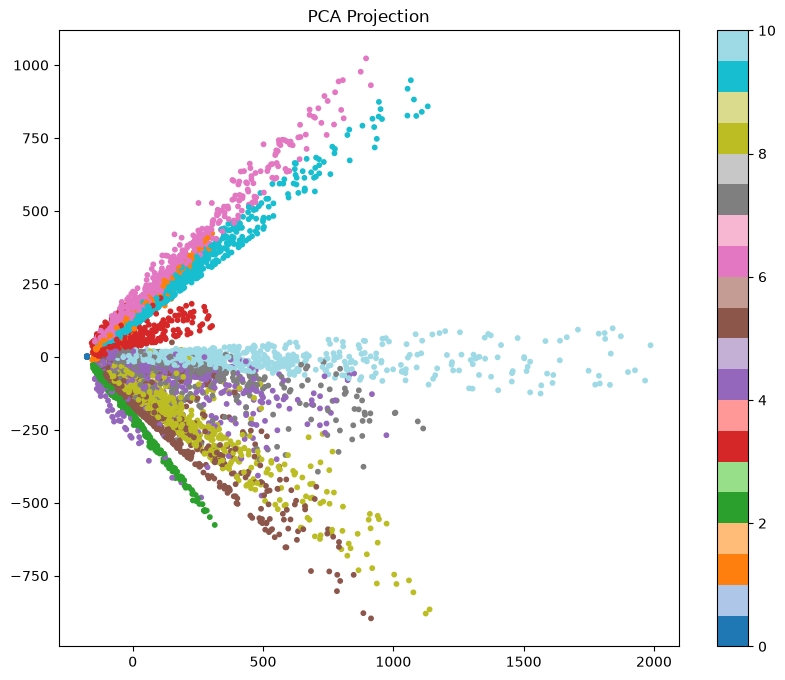

In [11]:
from sklearn.decomposition import PCA

with h5py.File(FILE,"r") as f:

    X = f["signals"][:]

X_flat = X.reshape(
    X.shape[0],
    -1
)

pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_flat)

plt.figure(figsize=(10,8))

scatter = plt.scatter(
    X_pca[:,0],
    X_pca[:,1],
    c=y_class,
    cmap="tab20",
    s=10
)

plt.colorbar(scatter)

plt.title("PCA Projection")
plt.show()

### t-SNE projection
**t-SNE** is a non-linear projection that keeps similar samples close together. It uses the first 5,000 samples only because it is slow. Most classes form their own clusters; a few fault types that involve the same phases (for example with and without ground) overlap, so those are the likely hard cases.

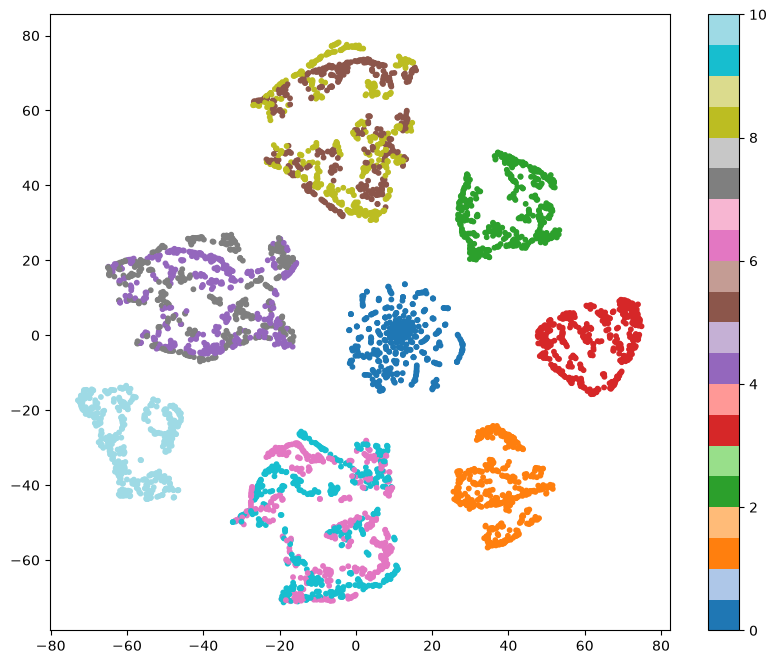

In [12]:
from sklearn.manifold import TSNE

tsne = TSNE(
    n_components=2,
    perplexity=30,
    random_state=42
)

X_tsne = tsne.fit_transform(X_flat[:5000])

plt.figure(figsize=(10,8))

plt.scatter(
    X_tsne[:,0],
    X_tsne[:,1],
    c=y_class[:5000],
    cmap='tab20',
    s=10
)

plt.colorbar()
plt.show()

### Quick baseline: random forest
Before building a deep model it is useful to know how well a simple one does. We train a scikit-learn random forest on the flattened signals with a stratified 80/20 split and print its accuracy.

**Note:** the accuracy is very high. That means this dataset is easy to separate with a simple model, but it should be read with care: the data comes from a simulation, and a random split can put near-identical conditions in both train and test sets. A fairer test uses held-out conditions (see the SNR and fault-resistance checks in `scripts/04_evaluate.py`).

In [13]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

X_train, X_test, y_train, y_test = train_test_split(
    X_flat,
    y_class,
    test_size=0.2,
    stratify=y_class,
    random_state=42
)

rf = RandomForestClassifier(
    n_estimators=200,
    n_jobs=-1
)

rf.fit(X_train, y_train)

pred = rf.predict(X_test)

print("Accuracy:", accuracy_score(y_test, pred))

Accuracy: 0.9996969696969698


## Summary

- The dataset has **16,500 samples**, 2001 time steps and 6 channels each.
- It is clean: **no missing values and no duplicate samples**.
- It is **balanced**: 1,500 samples per class, with fault locations spread along the line.
- Most classes separate well, so the CNN-LSTM pipeline (`main.py`, steps 1 to 4) can be trained and evaluated on it.